# SKIN DISEASE PREDICTION

The given dataset corresponds to the Erythemato-Squamous Diseases problem in dermatology. These diseases share similar clinical symptoms such as erythema and scaling, which makes diagnosis difficult. The objective of this analysis is to explore the dataset, understand its structure, perform preprocessing, and analyze its suitability for building predictive machine learning models.

The diseases considered in this dataset are:

1.Psoriasis

2.Seborrheic Dermatitis

3.Lichen Planus

4.Pityriasis Rosea

5.Chronic Dermatitis

6.Pityriasis Rubra Pilaris

### IMPORTING THE LIBRARIES 

In [1]:
 # importing the libraries

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns 

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import GridSearchCV

### LOADING THE DATASET 

In [2]:
df = pd.read_csv("skin_dataset.csv")


### BASIC CHECK

In [3]:
df.head()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,target
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45,3


In [4]:
df.tail()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,target
361,2,1,1,0,1,0,0,0,0,0,...,0,0,1,0,0,0,2,0,25,4
362,3,2,1,0,1,0,0,0,0,0,...,1,0,1,0,0,0,2,0,36,4
363,3,2,2,2,3,2,0,2,0,0,...,0,3,0,3,0,0,2,3,28,3
364,2,1,3,1,2,3,0,2,0,0,...,0,2,0,1,0,0,2,3,50,3
365,3,2,2,0,0,0,0,0,3,3,...,2,0,0,0,0,0,3,0,35,1


In [5]:
df.shape

(366, 35)

In [6]:
df.describe()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,target
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,...,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,2.068306,1.795082,1.549180,1.366120,0.633880,0.448087,0.166667,0.377049,0.614754,0.519126,...,0.393443,0.464481,0.456284,0.953552,0.453552,0.103825,0.114754,1.866120,0.554645,2.803279
std,0.664753,0.701527,0.907525,1.138299,0.908016,0.957327,0.570588,0.834147,0.982979,0.905639,...,0.849406,0.864899,0.954873,1.130172,0.954744,0.450433,0.488723,0.726108,1.105908,1.597803
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
50%,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,3.000000
75%,2.000000,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,0.000000,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,2.000000,0.000000,4.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,6.000000


### DISTRIBUTION OF DATA CHECK WITH HISTPLOT

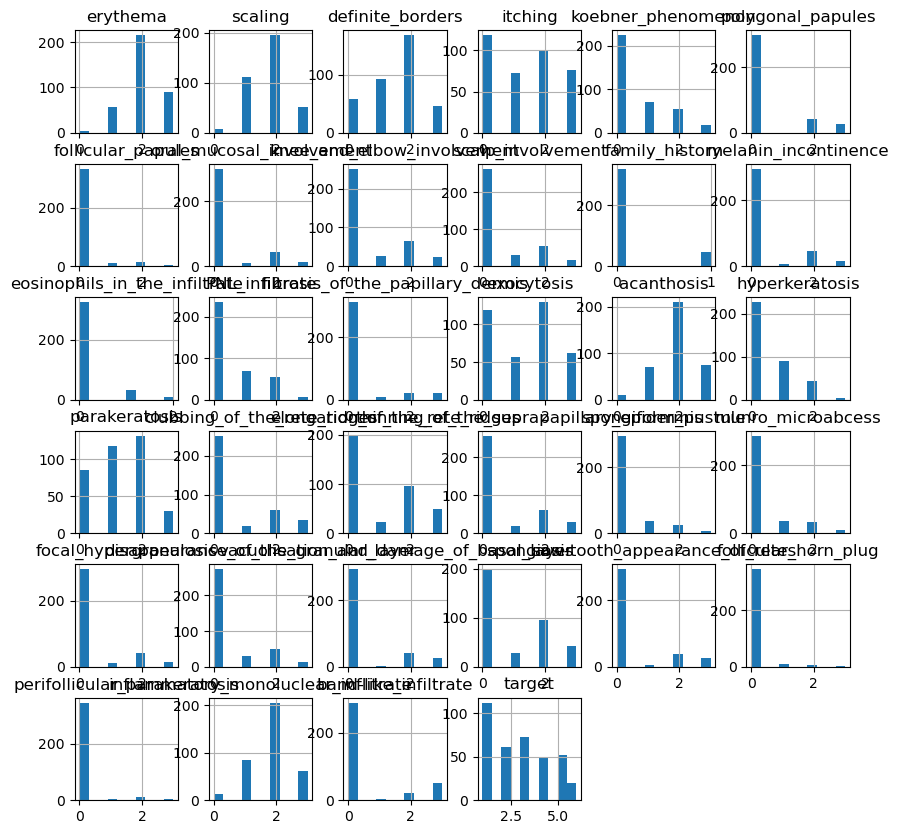

In [8]:
df.hist(figsize=(10,10))
plt.show()

### USING MATPLOT LIB

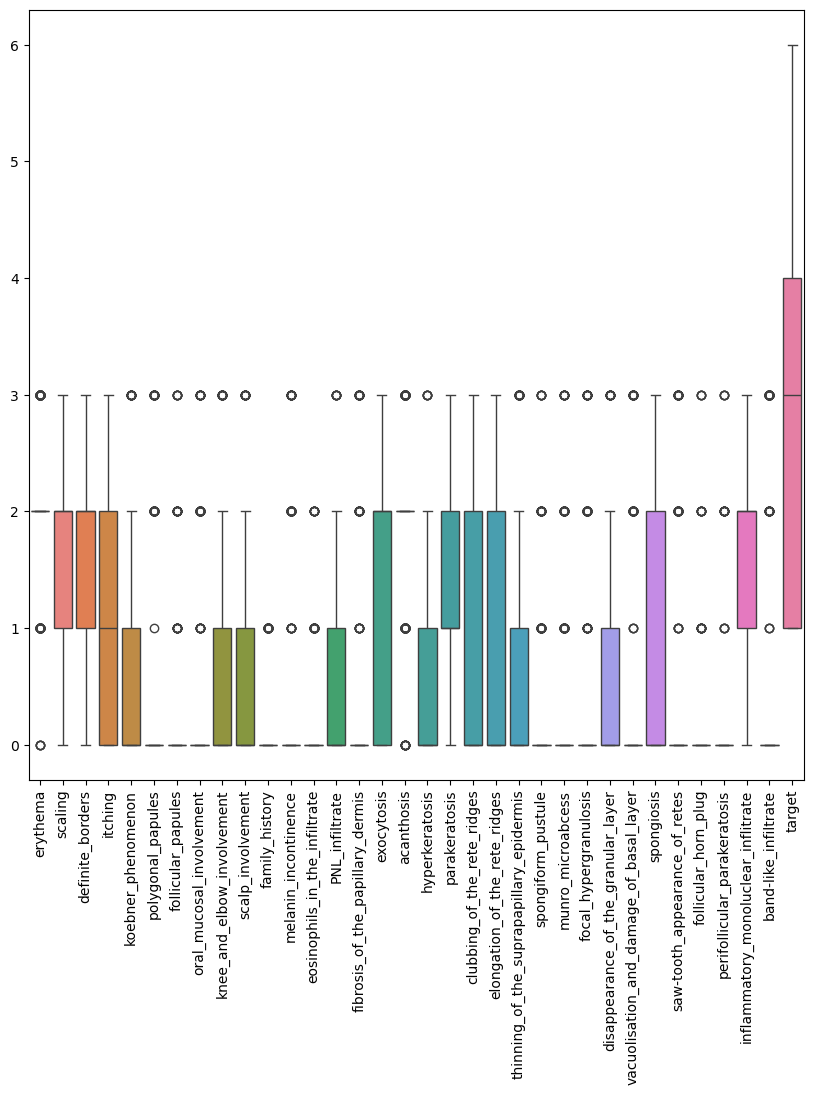

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))
sns.boxplot(data=df)
plt.xticks(rotation=90)
plt.show()


## NUL VALUES

In [10]:
df.isnull().sum()

erythema                                    0
scaling                                     0
definite_borders                            0
itching                                     0
koebner_phenomenon                          0
polygonal_papules                           0
follicular_papules                          0
oral_mucosal_involvement                    0
knee_and_elbow_involvement                  0
scalp_involvement                           0
family_history                              0
melanin_incontinence                        0
eosinophils_in_the_infiltrate               0
PNL_infiltrate                              0
fibrosis_of_the_papillary_dermis            0
exocytosis                                  0
acanthosis                                  0
hyperkeratosis                              0
parakeratosis                               0
clubbing_of_the_rete_ridges                 0
elongation_of_the_rete_ridges               0
thinning_of_the_suprapapillary_epi

In [11]:
df.isnull().sum().sum()


0

In [12]:
df[df.isnull().any(axis=1)]


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,target


In [13]:
df = df.replace("?", np.nan)


In [14]:
df.isnull().sum()


erythema                                    0
scaling                                     0
definite_borders                            0
itching                                     0
koebner_phenomenon                          0
polygonal_papules                           0
follicular_papules                          0
oral_mucosal_involvement                    0
knee_and_elbow_involvement                  0
scalp_involvement                           0
family_history                              0
melanin_incontinence                        0
eosinophils_in_the_infiltrate               0
PNL_infiltrate                              0
fibrosis_of_the_papillary_dermis            0
exocytosis                                  0
acanthosis                                  0
hyperkeratosis                              0
parakeratosis                               0
clubbing_of_the_rete_ridges                 0
elongation_of_the_rete_ridges               0
thinning_of_the_suprapapillary_epi

### CHECKING THE PERCENTAGE OF NULL VALUES IN EACH COL

In [15]:
(df.isnull().sum() / len(df)) * 100


erythema                                    0.000000
scaling                                     0.000000
definite_borders                            0.000000
itching                                     0.000000
koebner_phenomenon                          0.000000
polygonal_papules                           0.000000
follicular_papules                          0.000000
oral_mucosal_involvement                    0.000000
knee_and_elbow_involvement                  0.000000
scalp_involvement                           0.000000
family_history                              0.000000
melanin_incontinence                        0.000000
eosinophils_in_the_infiltrate               0.000000
PNL_infiltrate                              0.000000
fibrosis_of_the_papillary_dermis            0.000000
exocytosis                                  0.000000
acanthosis                                  0.000000
hyperkeratosis                              0.000000
parakeratosis                               0.

In [16]:
df = df.dropna(axis=1)


In [17]:
df.isnull().sum()

erythema                                    0
scaling                                     0
definite_borders                            0
itching                                     0
koebner_phenomenon                          0
polygonal_papules                           0
follicular_papules                          0
oral_mucosal_involvement                    0
knee_and_elbow_involvement                  0
scalp_involvement                           0
family_history                              0
melanin_incontinence                        0
eosinophils_in_the_infiltrate               0
PNL_infiltrate                              0
fibrosis_of_the_papillary_dermis            0
exocytosis                                  0
acanthosis                                  0
hyperkeratosis                              0
parakeratosis                               0
clubbing_of_the_rete_ridges                 0
elongation_of_the_rete_ridges               0
thinning_of_the_suprapapillary_epi

### CEHCKING DATA TYPES

In [18]:
df.dtypes

erythema                                    int64
scaling                                     int64
definite_borders                            int64
itching                                     int64
koebner_phenomenon                          int64
polygonal_papules                           int64
follicular_papules                          int64
oral_mucosal_involvement                    int64
knee_and_elbow_involvement                  int64
scalp_involvement                           int64
family_history                              int64
melanin_incontinence                        int64
eosinophils_in_the_infiltrate               int64
PNL_infiltrate                              int64
fibrosis_of_the_papillary_dermis            int64
exocytosis                                  int64
acanthosis                                  int64
hyperkeratosis                              int64
parakeratosis                               int64
clubbing_of_the_rete_ridges                 int64


In [19]:
df.duplicated().sum()

2

### USING MATPLOTLIB 

C:\Users\kiran\AppData\Local\Temp\ipykernel_15544\776089271.py:5: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure()


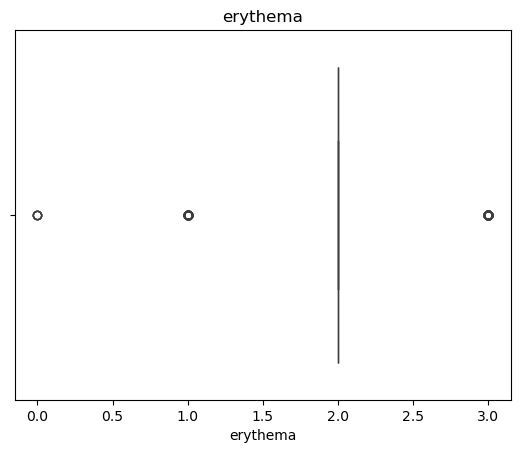

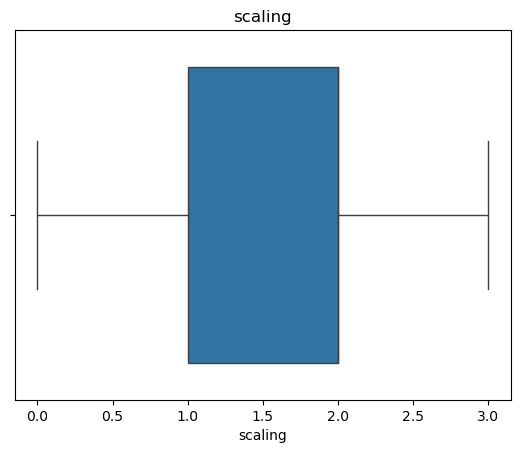

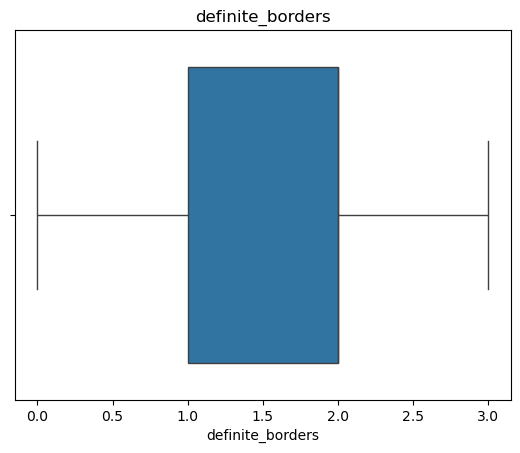

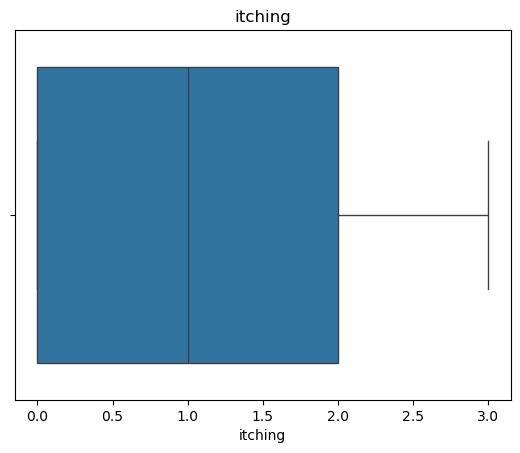

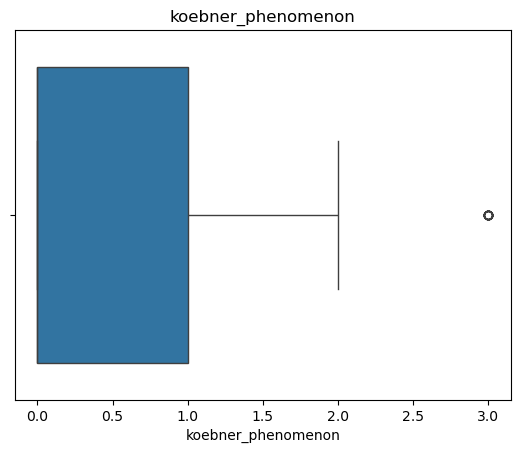

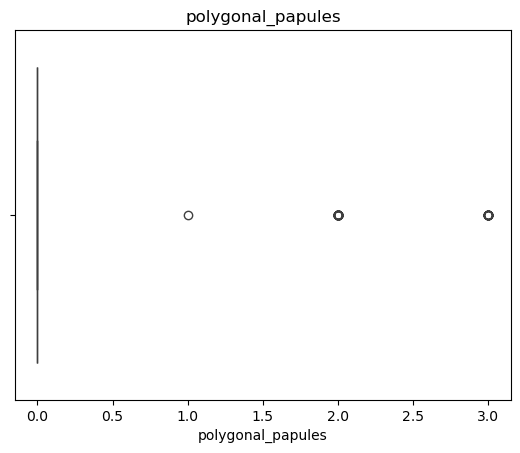

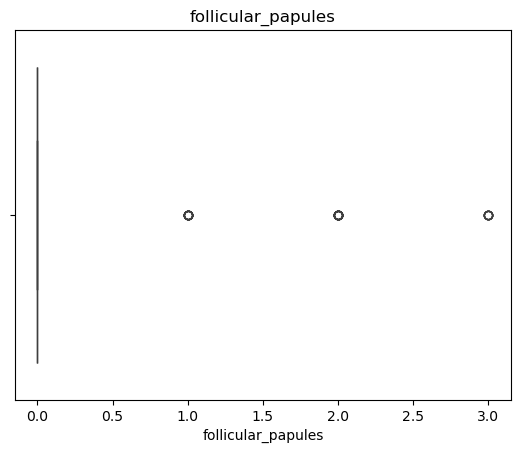

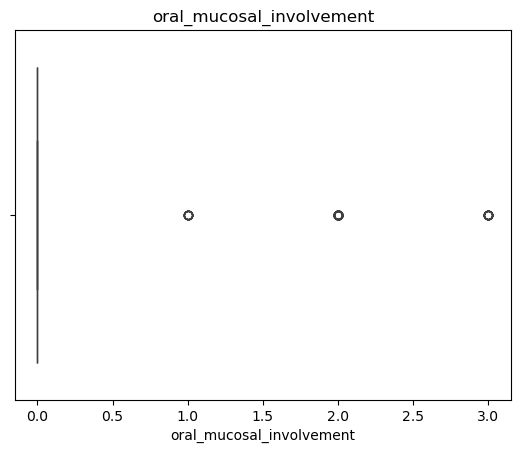

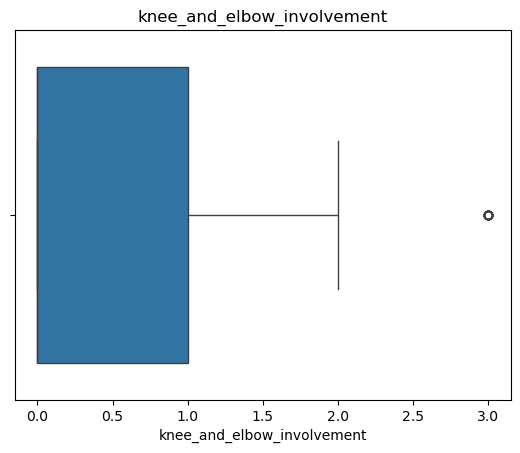

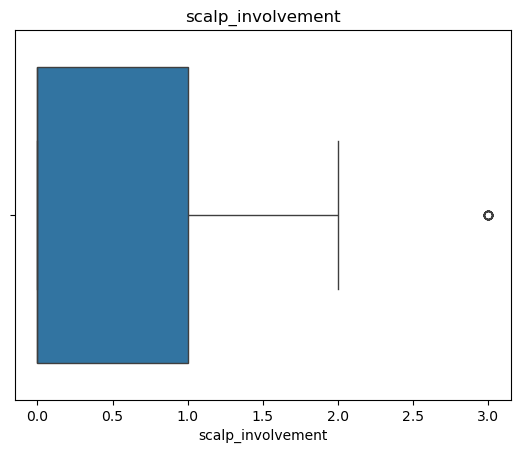

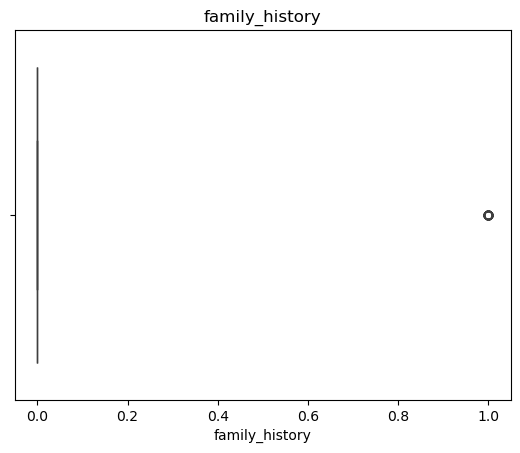

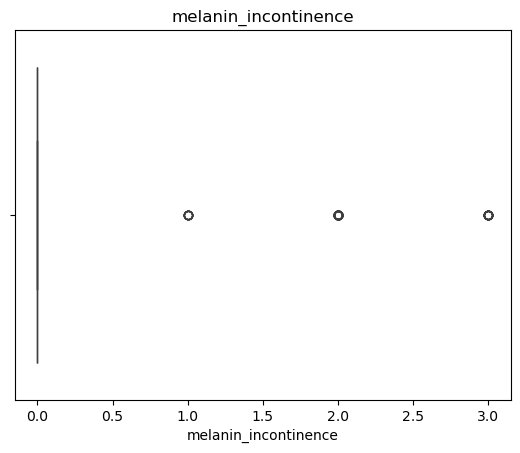

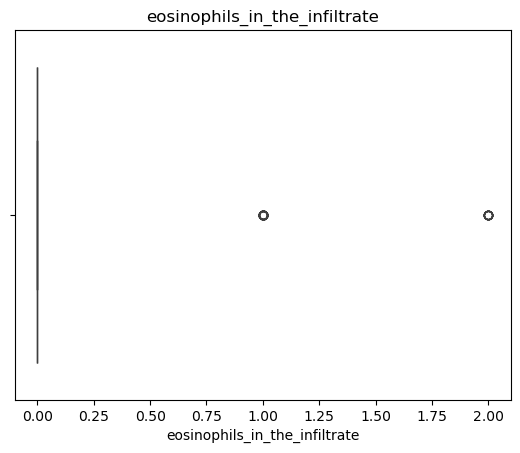

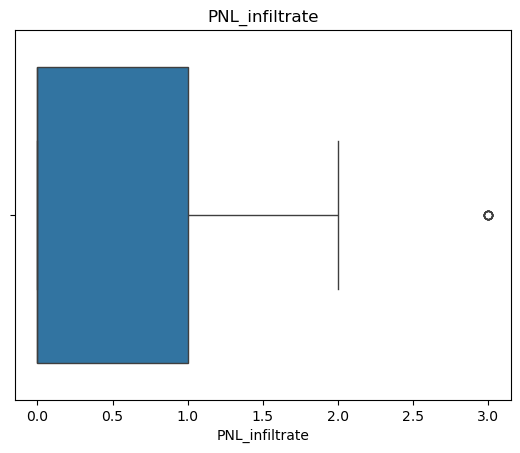

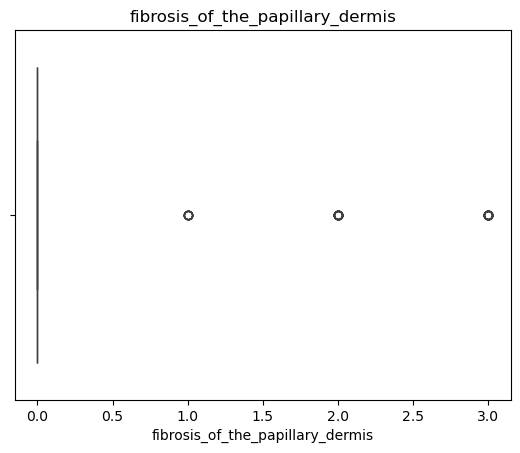

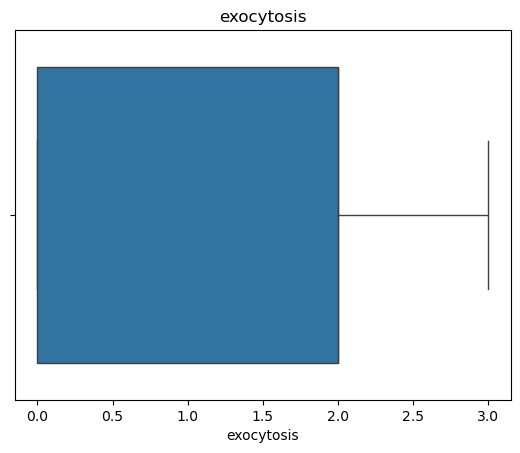

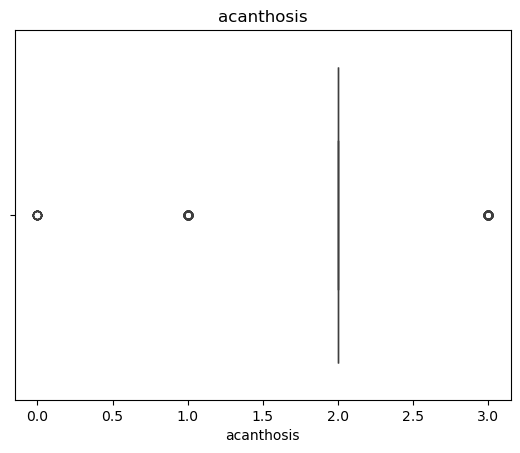

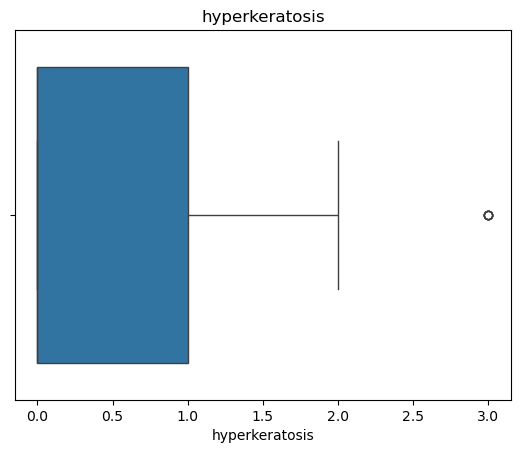

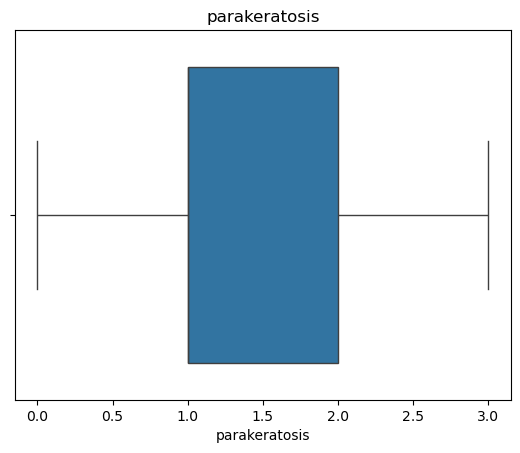

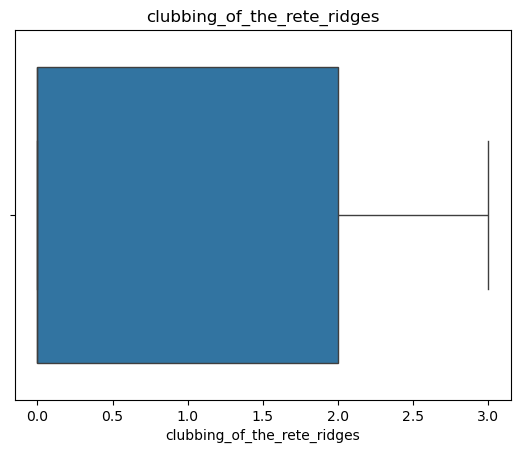

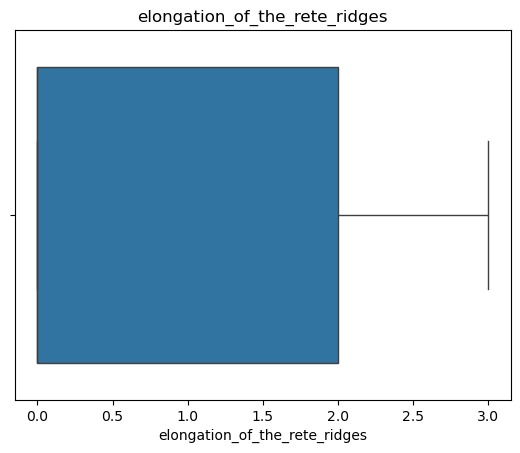

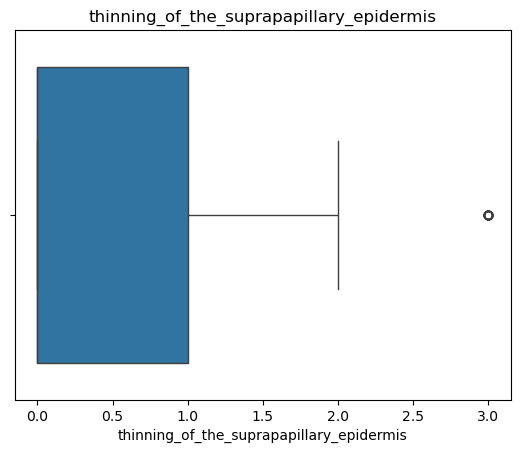

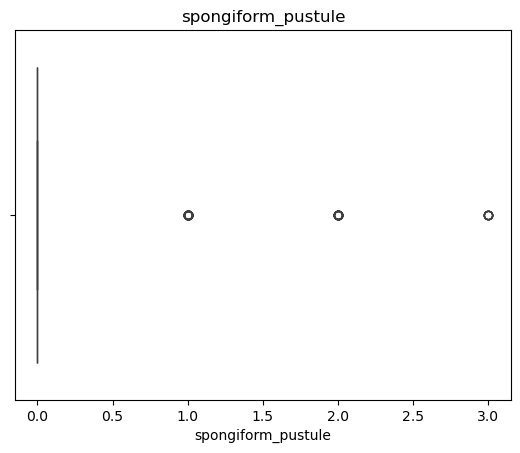

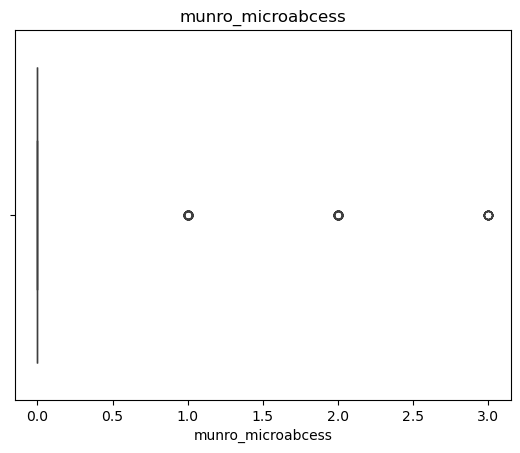

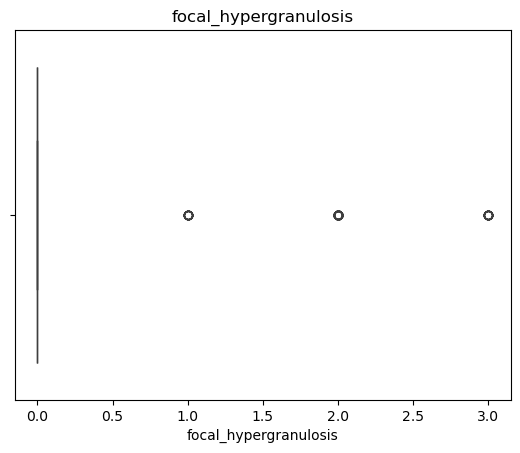

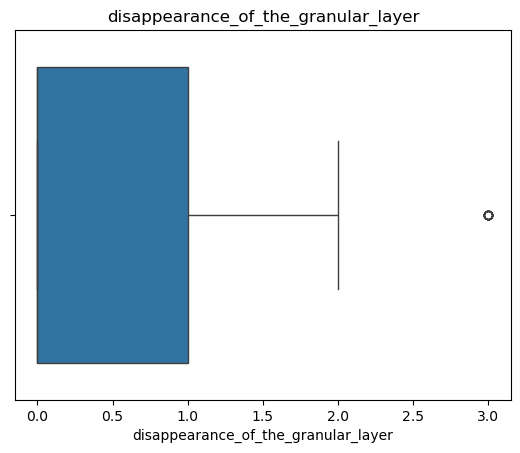

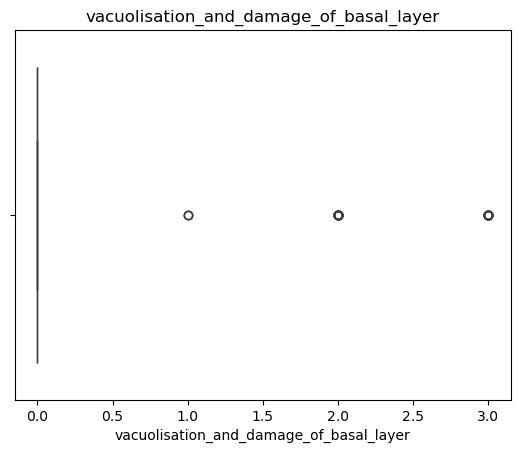

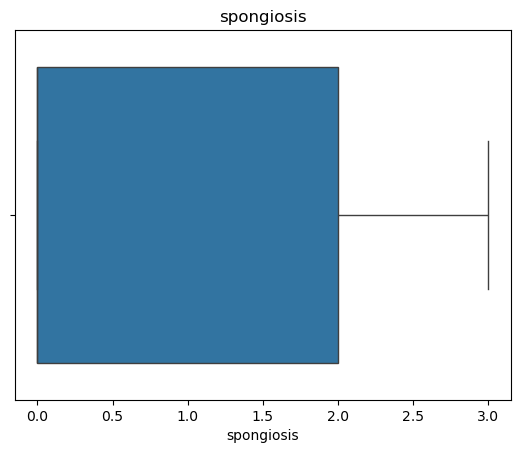

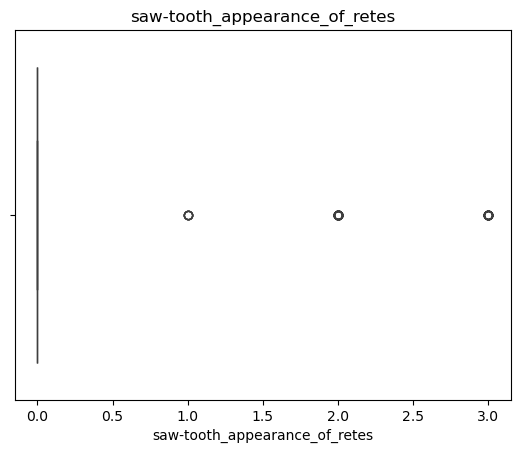

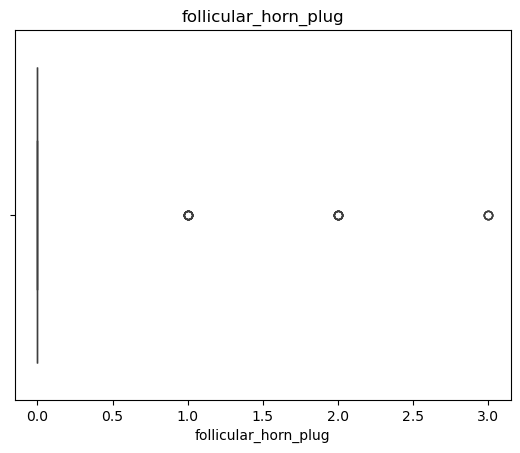

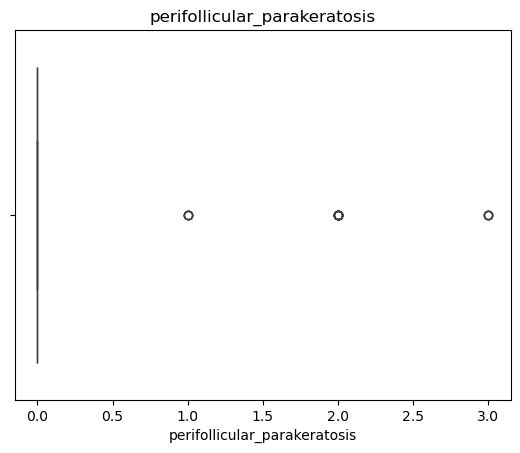

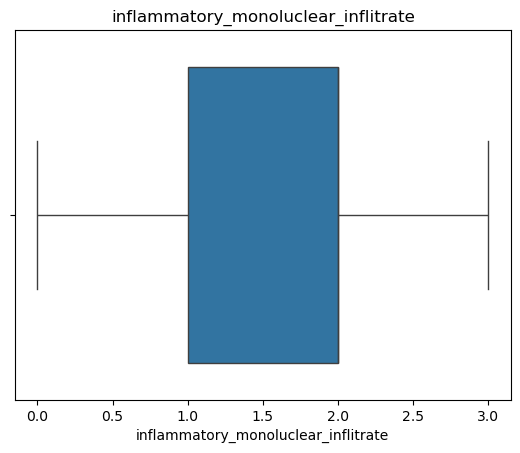

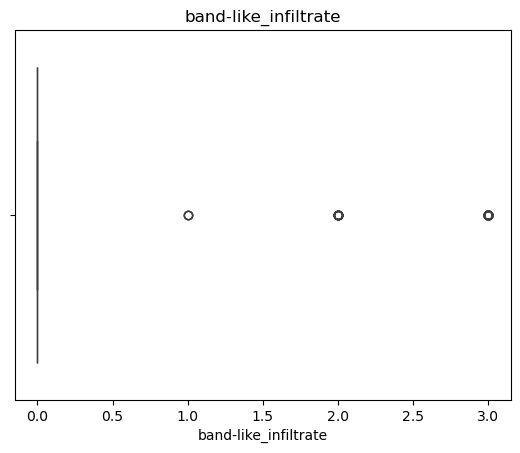

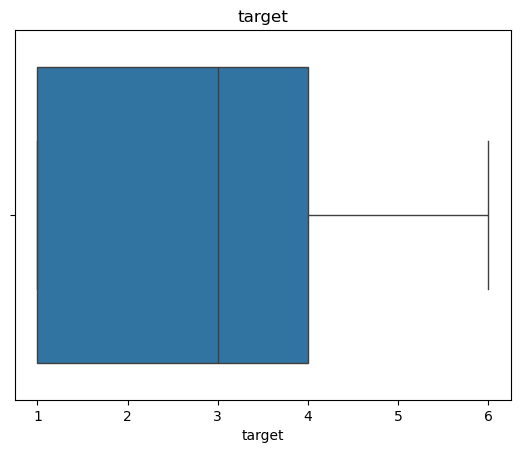

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in df.select_dtypes(include=['int64','float64']).columns:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(col)


#### CEHCKING THE NUMBER OF OUTLIERS IN A COL

In [21]:
import pandas as pd
import numpy as np

numeric = df.select_dtypes(include=['int64','float64'])

Q1 = numeric.quantile(0.25)
Q3 = numeric.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR

outliers = (numeric < lower) | (numeric > upper)
outliers.sum()   # number of outliers per column



erythema                                    151
scaling                                       0
definite_borders                              0
itching                                       0
koebner_phenomenon                           18
polygonal_papules                            69
follicular_papules                           33
oral_mucosal_involvement                     67
knee_and_elbow_involvement                   23
scalp_involvement                            16
family_history                               46
melanin_incontinence                         70
eosinophils_in_the_infiltrate                42
PNL_infiltrate                                7
fibrosis_of_the_papillary_dermis             54
exocytosis                                    0
acanthosis                                  156
hyperkeratosis                                5
parakeratosis                                 0
clubbing_of_the_rete_ridges                   0
elongation_of_the_rete_ridges           

<Axes: ylabel='erythema'>

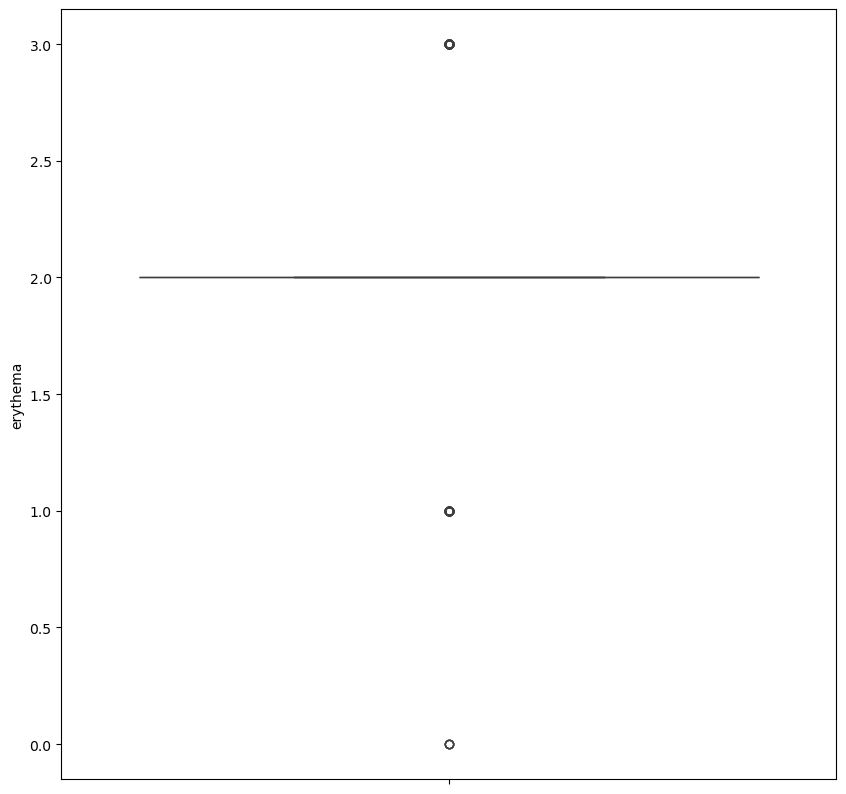

In [22]:
plt.figure(figsize=(10,10))
sns.boxplot(df['erythema'])


In [23]:
for col in df.select_dtypes(include='number').columns:
    lower = Q1[col] - 1.5 * IQR[col]
    upper = Q3[col] + 1.5 * IQR[col]
    df[col] = df[col].clip(lower, upper)


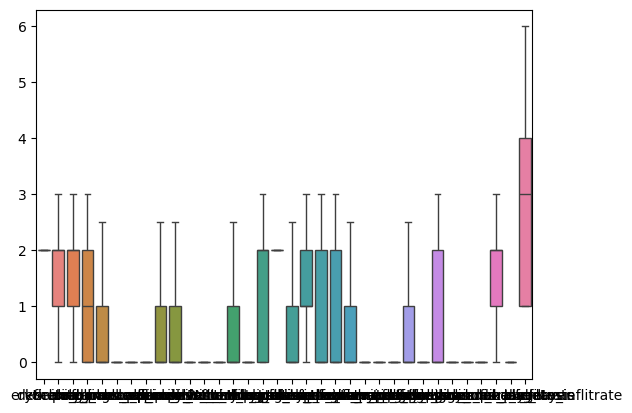

In [24]:
sns.boxplot(data=df)
plt.show()

### USING HEAT MAP TO KNOW THE CORRELATION

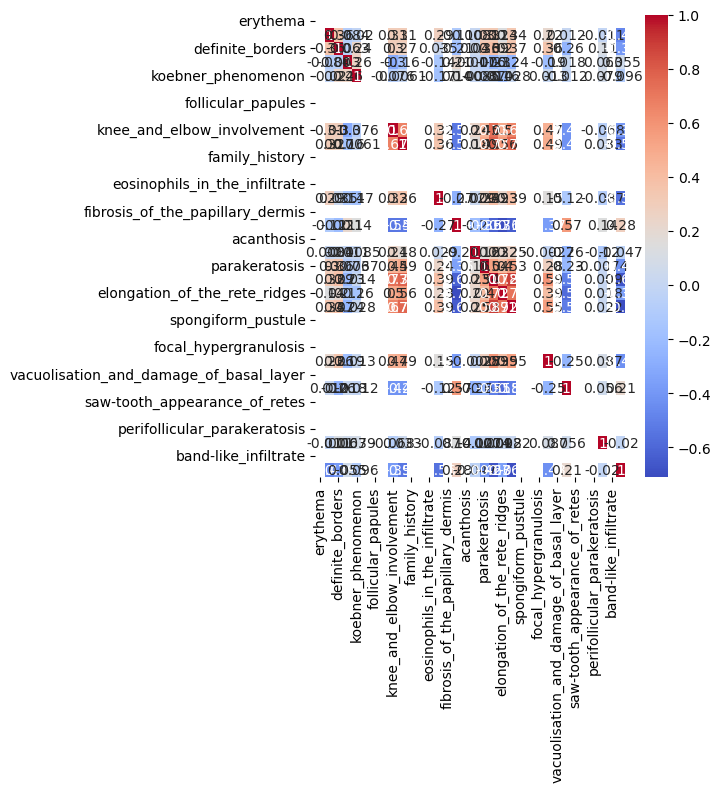

In [25]:
plt.figure(figsize=(5,6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.show()

### CEHCKING NULL VALUES

In [26]:
df.isnull().sum()

erythema                                    0
scaling                                     0
definite_borders                            0
itching                                     0
koebner_phenomenon                          0
polygonal_papules                           0
follicular_papules                          0
oral_mucosal_involvement                    0
knee_and_elbow_involvement                  0
scalp_involvement                           0
family_history                              0
melanin_incontinence                        0
eosinophils_in_the_infiltrate               0
PNL_infiltrate                              0
fibrosis_of_the_papillary_dermis            0
exocytosis                                  0
acanthosis                                  0
hyperkeratosis                              0
parakeratosis                               0
clubbing_of_the_rete_ridges                 0
elongation_of_the_rete_ridges               0
thinning_of_the_suprapapillary_epi

In [27]:
df['target'].value_counts()

target
1    112
3     72
2     61
5     52
4     49
6     20
Name: count, dtype: int64

### CLASIFYING X AND Y COLUMN

In [28]:
X = df.drop('target', axis=1)
y = df['target']


In [29]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

In [30]:
print(X.shape)
print(y.shape)

(366, 33)
(366,)


In [31]:
print(X.head())

   erythema  scaling  definite_borders  itching  koebner_phenomenon  \
0         2        2                 0        3                 0.0   
1         2        3                 3        2                 1.0   
2         2        1                 2        3                 1.0   
3         2        2                 2        0                 0.0   
4         2        3                 2        2                 2.0   

   polygonal_papules  follicular_papules  oral_mucosal_involvement  \
0                  0                   0                         0   
1                  0                   0                         0   
2                  0                   0                         0   
3                  0                   0                         0   
4                  0                   0                         0   

   knee_and_elbow_involvement  scalp_involvement  ...  munro_microabcess  \
0                         1.0                0.0  ...                  0   


In [51]:
y.value_counts()

target
1    112
3     72
2     61
5     52
4     49
6     20
Name: count, dtype: int64

In [32]:
print(y.head())

0    2
1    1
2    3
3    1
4    3
Name: target, dtype: int64


### USING GRAPH TO FIND THE TARGET COLUMN 

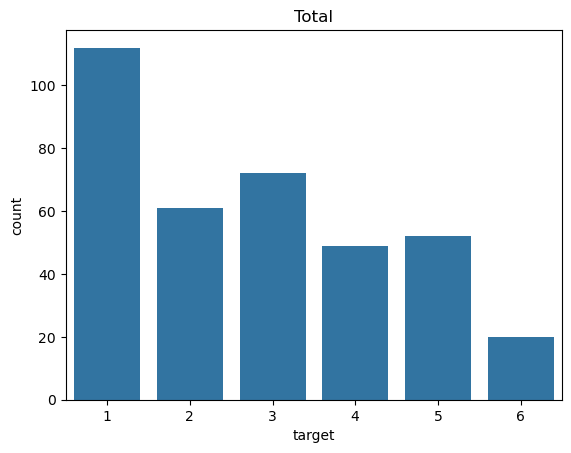

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x=y)
plt.title("Total")
plt.show()

### TRAIN TEST SLPIT 


In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(y_train.value_counts(normalize=True) * 100)
print(y_test.value_counts(normalize=True) * 100)


target
1    30.479452
3    19.520548
2    16.780822
5    14.383562
4    13.356164
6     5.479452
Name: proportion, dtype: float64
target
1    31.081081
3    20.270270
2    16.216216
4    13.513514
5    13.513514
6     5.405405
Name: proportion, dtype: float64


### BALANCING DATA

In [52]:
from imblearn.over_sampling import SMOTE

smote = SMOTE()
X_res, y_res = smote.fit_resample(X_train, y_train)
y_res.value_counts()

target
3    89
5    89
4    89
1    89
2    89
6    89
Name: count, dtype: int64

### USING StandardScaler

In [36]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import GridSearchCV
model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)


### LOGESTIC REGRESSION MODEL AND PREDICTION

In [38]:
model.fit(X_train, y_train)


LogisticRegression(class_weight='balanced', max_iter=1000)

In [39]:
# PREDICTION AND CLASIIFICATION         

y_pred = model.predict(X_test)
accuracy_score(y_test, y_pred)


0.9594594594594594

### CLASSIFICATION REPORT

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import GridSearchCV

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.91      0.83      0.87        12
           3       1.00      1.00      1.00        15
           4       0.90      0.90      0.90        10
           5       1.00      1.00      1.00        10
           6       0.80      1.00      0.89         4

    accuracy                           0.96        74
   macro avg       0.93      0.96      0.94        74
weighted avg       0.96      0.96      0.96        74



## svm (support vector machine)

In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


### USING SVM MODEL

In [45]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf')
svm.fit(X_train, y_train)

print("SVM Accuracy:", svm.score(X_test, y_test))


SVM Accuracy: 0.9594594594594594


### USING RANDOM FOREST CLASSIIFIER

In [46]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train, y_train)
print("Random Forest Accuracy:", rf.score(X_test, y_test))


Random Forest Accuracy: 0.918918918918919


### USING KNN MODEL 


In [47]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

print("KNN Accuracy:", knn.score(X_test, y_test))


KNN Accuracy: 0.8918918918918919


### logestic regression accuracy : 0.9594594594594594
### SVM Accuracy                 : 0.9594594594594594
### Random Forest Accuracy       : 0.918918918918919
### KNN Accuracy                 : 0.8918918918918919

### As per above accuracy we can see that LOGESTIC REGRESSION and  SVM are in high !!!!

In [54]:
## NEW DATA PREDICTION WITH SVM

new_patient = [[
    2,2,2,1,0,0,0,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
    0,0,0,1,0,0,0,2,0
]]

new_patient = scaler.transform(new_patient)
prediction = svm.predict(new_patient)

print("Predicted Disease Class:", prediction[0])


Predicted Disease Class: 5


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


###  ANALYISIS REPORT

The given dataset is appropriate for building multi-class classification models for skin disease prediction. Proper preprocessing, scaling, and handling of class imbalance are crucial for achieving reliable performance. Classical machine learning algorithms such as SVM and Random Forest are particularly effective for this type of medical tabular data.

This data analysis forms a strong foundation for developing predictive models and further performance evaluation.

 ####  Disclaimer

This analysis and any predictive models developed using this dataset are intended for academic and research purposes only and should not be considered a substitute for professional medical diagnosis.

I’ve created a complete, well-structured Data Analysis Report .